# 03 – Kho dữ liệu (Data Warehouse) và OLAP
Kho dữ liệu SQLite theo mô hình *fact constellation*: 3 bảng fact dùng chung 7 bảng chiều, kiểm tra chất lượng, 2 khối OLAP (mỗi khối 8 cuboid) và các phép OLAP.

| Bước | Nội dung | Kết quả chính |
|---|---|---|
| 0 | Cấu hình, kiểm tra file CSV | đường dẫn, hằng số, quy tắc loại hàng phi hàng hóa |
| 1 | ETL các bảng chiều | `dim_date`, `dim_product`, `dim_household`, `dim_campaign`, `dim_coupon`, `bridge_coupon_product`, `dim_store` |
| 2 | ETL 3 bảng fact | `fact_sales`, `fact_coupon_redemption`, `fact_campaign_response` + chỉ mục |
| 3 | Kiểm tra chất lượng và toàn vẹn tham chiếu | đối soát với CSV, kiểm tra khóa ngoại, cờ chất lượng |
| 4 | Dựng 2 khối dữ liệu (CUBE BY, 2³ = 8 cuboid mỗi khối) | các bảng `cuboid_*`, thống kê lattice |
| 5 | Các phép OLAP + 6 biểu đồ | roll-up, drill-down, slice, dice, pivot, drill-across, drill-through |
| 6 | Sơ đồ fact constellation và lattice cuboid | 2 hình PNG |
| 7 | Đối chiếu số liệu chính | bảng kiểm tra cuối |

Bảng kết quả lưu ở `outputs/dw/`, hình ở `figures/dw/`. File SQLite (~340 MB) lưu ở `outputs/` khi chạy trên máy, ở ổ tạm `/content` khi chạy trên Colab.

In [1]:
# Chạy trên Google Colab: kết nối Drive và chuyển vào thư mục notebooks của dự án (máy cá nhân thì bỏ qua)
import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir('/content/drive/MyDrive/DM_Nhom3_Final/notebooks')  # sửa nếu để thư mục dự án ở chỗ khác
except ImportError:
    pass
print(os.getcwd())

/home/claude/DM_Nhom3_Final/notebooks


---
## Bước 0 – Cấu hình và kiểm tra dữ liệu nguồn
Đường dẫn, các hằng số dùng chung và quy tắc loại hàng phi hàng hóa (giống notebook 02).

In [2]:
# ▶ 0.1 Thư viện
import os, sys, itertools, sqlite3, shutil
from pathlib import Path
import numpy as np
import pandas as pd
IN_COLAB = "google.colab" in sys.modules

# ▶ 0.2 Đường dẫn (tương đối so với thư mục notebooks/)
DATA_DIR = Path("../data")
OUT_DIR  = Path("../outputs")
TAB_DIR  = OUT_DIR / "dw"
FIG_DIR  = Path("../figures/dw")
DW_PATH  = Path("/content/dunnhumby_dw.sqlite") if IN_COLAB else OUT_DIR / "dunnhumby_dw.sqlite"   # SQLite ~340 MB
for d_ in (FIG_DIR, TAB_DIR):
    d_.mkdir(parents=True, exist_ok=True)

# ▶ 0.3 Kiểm tra file CSV (causal_data.csv không dùng nên không bắt buộc)
EXPECTED_CSV = ["transaction_data.csv", "product.csv", "hh_demographic.csv", "campaign_table.csv",
                "campaign_desc.csv", "coupon.csv", "coupon_redempt.csv"]
missing = [n for n in EXPECTED_CSV if not (DATA_DIR / n).exists()]
if missing:
    raise FileNotFoundError(f"Không tìm thấy {missing} trong {DATA_DIR.resolve()}")
csv_path = lambda name: DATA_DIR / name
for n in EXPECTED_CSV:
    print(f"  {n:24s} {(DATA_DIR / n).stat().st_size/1e6:8.1f} MB")
print("Bảng kết quả:", TAB_DIR, "| Hình:", FIG_DIR, "| SQLite:", DW_PATH)

# ▶ 0.4 Hằng số dùng chung
# DAY là số thứ tự ngày tương đối (không có ngày lịch thật)
LAST_DAY = 719              # ngày lớn nhất xuất hiện trong giao dịch (711) hoặc kết thúc chiến dịch (719) -> DimTime 719 dòng
MAX_TX_DAY = 711            # ngày cuối có giao dịch; ngày sau đó không có ánh xạ WEEK_NO -> để NULL
WEEKS_PER_BLOCK = 13        # "khối 13 tuần": nhóm tuần theo quy ước (không phải quý lịch)
PRE_WINDOW_DAYS = 90        # cửa sổ "trước chiến dịch" (biến mở rộng, xem mục Giới hạn)

# Quy tắc loại hàng phi hàng hóa (giống notebook 02)
NON_MERCH_DEPTS = {"KIOSK-GAS", "MISC SALES TRAN", "MISC. TRANS.", "COUP/STR & MFG", "CHARITABLE CONT",
                   "POSTAL CENTER", "CNTRL/STORE SUP", "GM MERCH EXP", "UNKNOWN"}      # UNKNOWN = nhãn department trống
NON_MERCH_COMMODITIES = {"COUPON/MISC ITEMS", "NO COMMODITY DESCRIPTION", "COUPONS/STORE & MFG", "COUPON", "FUEL",
                         "UNKNOWN", "(CORP USE ONLY)", "MISCELLANEOUS(CORP USE ONLY)"}

def week_of_day(day):
    """WEEK_NO của Dunnhumby: tuần 1 gồm ngày 1-5, các tuần sau bắt đầu từ ngày 6 (mỗi tuần 7 ngày)."""
    day = np.asarray(day)
    return np.where(day < 6, 1, (day - 6) // 7 + 2)

  transaction_data.csv        141.7 MB
  product.csv                   6.4 MB
  hh_demographic.csv            0.0 MB
  campaign_table.csv            0.1 MB
  campaign_desc.csv             0.0 MB
  coupon.csv                    2.8 MB
  coupon_redempt.csv            0.1 MB
Bảng kết quả: ../outputs/dw | Hình: ../figures/dw | SQLite: ../outputs/dunnhumby_dw.sqlite


---
## Bước 1 – ETL: xây dựng các bảng chiều (dimension tables)
Extract từ CSV → Transform (làm sạch, tạo thuộc tính phân cấp) → Load vào SQLite.
Tạo: `dim_date` (day < week < khối 13 tuần), `dim_product` (department > commodity > sub_commodity > product), `dim_household`
(gộp nhân khẩu học; hộ không có thông tin → `Unknown`), `dim_campaign`, `dim_coupon` + `bridge_coupon_product` (khử trùng), `dim_store`.

In [3]:
import sqlite3
import numpy as np
import pandas as pd

def read(name, **kw):
    return pd.read_csv(csv_path(name), **kw)

if DW_PATH.exists():
    DW_PATH.unlink()                  # xây kho mới hoàn toàn mỗi lần chạy lại từ Bước 1
con = sqlite3.connect(DW_PATH)

In [4]:
# ▶ dim_date (DimTime): day < week < week_block. KHÔNG suy ra tháng/quý/năm lịch.
d = pd.DataFrame({"date_key": np.arange(1, LAST_DAY + 1)})
has_week = d.date_key <= MAX_TX_DAY                      # ngày ngoài khoảng giao dịch: week_no = NULL (không tự suy diễn)
d["week_no"] = pd.Series(week_of_day(d.date_key), dtype="Int64").where(has_week)
d["day_in_week"] = pd.Series(np.where(d.date_key < 6, d.date_key, (d.date_key - 6) % 7 + 1), dtype="Int64").where(has_week)
d["week_block"] = ((d.week_no - 1) // WEEKS_PER_BLOCK + 1).astype("Int64")
d["block_label"] = ("B" + d.week_block.astype(str)).where(has_week)
d.to_sql("dim_date", con, if_exists="replace", index=False)

719

In [5]:
# ▶ dim_product: department > commodity > sub_commodity > product
p = read("product.csv")
for c in p.select_dtypes(include=["object", "string"]):
    p[c] = p[c].str.strip()
p = p.replace({"": np.nan})
p["DEPARTMENT"] = p.DEPARTMENT.fillna("UNKNOWN")
p["is_private_label"] = (p.BRAND == "Private").astype(int)
p["is_non_merchandise"] = (p.DEPARTMENT.isin(NON_MERCH_DEPTS) | p.COMMODITY_DESC.isin(NON_MERCH_COMMODITIES)).astype(int)
p.columns = [c.lower() for c in p.columns]
p = p.rename(columns={"commodity_desc": "commodity", "sub_commodity_desc": "sub_commodity",
                      "curr_size_of_product": "pack_size"})
p.to_sql("dim_product", con, if_exists="replace", index=False)

92353

In [6]:
# ▶ dim_household: gộp nhân khẩu học (chỉ 801/2500 hộ có) -> 'Unknown' cho hộ không có thông tin
tx_hh = read("transaction_data.csv", usecols=["household_key"]).household_key.unique()
hh = read("hh_demographic.csv")
h = pd.DataFrame({"household_key": np.sort(tx_hh)}).merge(hh, on="household_key", how="left")
h["has_demographics"] = h.AGE_DESC.notna().astype(int)
for c in ["AGE_DESC", "MARITAL_STATUS_CODE", "INCOME_DESC", "HOMEOWNER_DESC", "HH_COMP_DESC",
          "HOUSEHOLD_SIZE_DESC", "KID_CATEGORY_DESC"]:
    h[c] = h[c].fillna("Unknown")
h = h.rename(columns={"AGE_DESC": "age_group", "MARITAL_STATUS_CODE": "marital_status",
                      "INCOME_DESC": "income_desc", "HOMEOWNER_DESC": "homeowner",
                      "HH_COMP_DESC": "hh_composition", "HOUSEHOLD_SIZE_DESC": "household_size",
                      "KID_CATEGORY_DESC": "kid_category"})
low = {"Under 15K", "15-24K", "25-34K"}
mid = {"35-49K", "50-74K"}
high = {"75-99K", "100-124K", "125-149K", "150-174K", "175-199K", "200-249K", "250K+"}
h["income_group"] = np.select([h.income_desc.isin(low), h.income_desc.isin(mid), h.income_desc.isin(high)],
                              ["Low (<35K)", "Mid (35-74K)", "High (75K+)"], "Unknown")
h.to_sql("dim_household", con, if_exists="replace", index=False)

2500

In [7]:
# ▶ dim_campaign
cd = read("campaign_desc.csv").rename(columns={"DESCRIPTION": "campaign_type", "CAMPAIGN": "campaign_key",
                                               "START_DAY": "start_day", "END_DAY": "end_day"})
cd["duration_days"] = cd.end_day - cd.start_day + 1
cd = cd.merge(d[["date_key", "week_no"]].rename(columns={"date_key": "start_day", "week_no": "start_week_no"}), on="start_day")
cd = cd.sort_values("campaign_key")
cd.to_sql("dim_campaign", con, if_exists="replace", index=False)

30

In [8]:
# ▶ dim_coupon (mỗi COUPON_UPC một dòng) + bridge_coupon_product (coupon x sản phẩm x chiến dịch, đã khử trùng)
cp = read("coupon.csv", dtype={"COUPON_UPC": str}).rename(columns={"COUPON_UPC": "coupon_upc", "PRODUCT_ID": "product_id",
                                                                   "CAMPAIGN": "campaign_key"})
n_raw = len(cp)
cp = cp.drop_duplicates()
print("coupon: ", n_raw, "->", len(cp), "dòng sau khử trùng")
dc = cp.groupby("coupon_upc").agg(n_products=("product_id", "nunique"), n_campaigns=("campaign_key", "nunique")).reset_index()
dc.to_sql("dim_coupon", con, if_exists="replace", index=False)
cp.to_sql("bridge_coupon_product", con, if_exists="replace", index=False)

coupon:  124548 -> 119384 dòng sau khử trùng


119384

In [9]:
# ▶ dim_store (store_tier suy ra từ tổng doanh số - thuộc tính dẫn xuất, tính ở bước 02)
stores = read("transaction_data.csv", usecols=["STORE_ID"]).STORE_ID.unique()
pd.DataFrame({"store_id": np.sort(stores)}).to_sql("dim_store", con, if_exists="replace", index=False)

con.commit()
for t in ["dim_date", "dim_product", "dim_household", "dim_campaign", "dim_coupon",
          "bridge_coupon_product", "dim_store"]:
    print(f"{t:24s}", con.execute(f"select count(*) from {t}").fetchone()[0])
con.close()

dim_date                 719
dim_product              92353
dim_household            2500
dim_campaign             30
dim_coupon               1135
bridge_coupon_product    119384
dim_store                582


---
## Bước 2 – ETL: nạp 3 bảng fact (fact constellation)
`fact_sales` (grain: một dòng sản phẩm trong một giỏ), `fact_coupon_redemption` (hộ × ngày × coupon được đổi),
`fact_campaign_response` (hộ × chiến dịch được nhắm tới). `causal_data` **không dùng**.
Giữ các cột `*_raw` để truy vết và cờ `is_analysis_eligible` / `exclusion_reason` thay vì xóa dòng.

In [10]:
import sqlite3
import numpy as np
import pandas as pd

con = sqlite3.connect(DW_PATH)
read = lambda n, **kw: pd.read_csv(csv_path(n), **kw)

In [11]:
# ▶ 1) fact_sales - grain: một dòng sản phẩm trong một giỏ hàng
t = read("transaction_data.csv").rename(columns={
    "household_key": "household_key", "BASKET_ID": "basket_id", "DAY": "date_key", "PRODUCT_ID": "product_id",
    "QUANTITY": "quantity", "SALES_VALUE": "sales_value", "STORE_ID": "store_id", "RETAIL_DISC": "retail_disc_raw",
    "TRANS_TIME": "trans_time", "WEEK_NO": "week_no", "COUPON_DISC": "coupon_disc_raw",
    "COUPON_MATCH_DISC": "coupon_match_disc_raw"})
assert (week_of_day(t.date_key) == t.week_no).all(), "Công thức tuần không khớp WEEK_NO"
t = t.drop(columns="week_no")                      # week_no đã nằm trong dim_date
t["trans_hour"] = (t.trans_time // 100).clip(0, 23)
# Giảm giá: nguồn ghi số âm -> chuẩn hóa thành số dương (RETAIL_DISC > 0 là sai dấu -> 0); giữ cột *_raw để truy vết
t["retail_disc_amount"] = (-t.retail_disc_raw).clip(lower=0)
t["coupon_disc_amount"] = (-t.coupon_disc_raw).clip(lower=0)
t["coupon_match_disc_amount"] = (-t.coupon_match_disc_raw).clip(lower=0)
t["is_valid_sale"] = ((t.quantity > 0) & (t.sales_value > 0)).astype(int)
prod = pd.read_sql("select product_id, is_non_merchandise from dim_product", con)
t = t.merge(prod, on="product_id", how="left")
t["is_non_merchandise"] = t.is_non_merchandise.fillna(0).astype(int)
t["is_analysis_eligible"] = ((t.is_valid_sale == 1) & (t.is_non_merchandise == 0)).astype(int)
t["exclusion_reason"] = np.select([t.is_valid_sale == 0, t.is_non_merchandise == 1],
                                  ["SALES_VALUE<=0 or QUANTITY=0", "NON_MERCHANDISE"], None)
t["has_coupon"] = ((t.coupon_disc_raw < 0) | (t.coupon_match_disc_raw < 0)).astype(int)
t.insert(0, "sales_line_id", np.arange(1, len(t) + 1))
t.to_sql("fact_sales", con, if_exists="replace", index=False, chunksize=200_000)
print("fact_sales", len(t))

# dim_store: thuộc tính dẫn xuất store_tier (tứ phân vị doanh số)
ss = t[t.is_analysis_eligible == 1].groupby("store_id").sales_value.sum()
tier = pd.qcut(ss.rank(method="first"), 4, labels=["Q1-nhỏ", "Q2", "Q3", "Q4-lớn"]).astype(str)
ds = pd.DataFrame({"store_id": t.store_id.unique()}).sort_values("store_id")
ds["store_tier"] = ds.store_id.map(tier).fillna("No-sales")
ds["total_sales_value"] = ds.store_id.map(ss).fillna(0).round(2)
ds.to_sql("dim_store", con, if_exists="replace", index=False)

fact_sales 2595732


582

In [12]:
# ▶ 2) fact_coupon_redemption - grain: hộ x ngày x coupon được đổi
r = read("coupon_redempt.csv", dtype={"COUPON_UPC": str}).rename(columns={"DAY": "date_key", "COUPON_UPC": "coupon_upc",
                                               "CAMPAIGN": "campaign_key"})
r.insert(0, "redemption_id", np.arange(1, len(r) + 1))
r["redeemed_qty"] = 1
r.to_sql("fact_coupon_redemption", con, if_exists="replace", index=False)
print("fact_coupon_redemption", len(r))

fact_coupon_redemption 2318


In [13]:
# ▶ 3) fact_campaign_response - grain: hộ x chiến dịch được nhắm tới
ct = read("campaign_table.csv").rename(columns={"CAMPAIGN": "campaign_key", "DESCRIPTION": "campaign_type_tbl"})
cd = pd.read_sql("select campaign_key, start_day, end_day from dim_campaign", con)
f = ct.merge(cd, on="campaign_key")
agg_r = r.groupby(["household_key", "campaign_key"]).agg(
    n_redemptions=("redeemed_qty", "sum"), n_distinct_coupons=("coupon_upc", "nunique"),
    first_redeem_day=("date_key", "min")).reset_index()
f = f.merge(agg_r, how="left", on=["household_key", "campaign_key"])
for c in ["n_redemptions", "n_distinct_coupons"]:
    f[c] = f[c].fillna(0).astype(int)
f["redeemed_flag"] = (f.n_redemptions > 0).astype(int)

# Chi tiêu theo ngày/hộ (chỉ dòng hợp lệ, không tính hàng phi hàng hóa) để tính cửa sổ thời gian
v = t[t.is_analysis_eligible == 1]
daily = v.groupby(["household_key", "date_key"]).agg(spend=("sales_value", "sum"),
                                                     baskets=("basket_id", "nunique")).reset_index()
m = f[["household_key", "campaign_key", "start_day", "end_day"]].merge(daily, on="household_key")
inw = m[(m.date_key >= m.start_day) & (m.date_key <= m.end_day)].groupby(["household_key", "campaign_key"]).agg(
    spend_in_window=("spend", "sum"), baskets_in_window=("baskets", "sum")).reset_index()
pre = m[(m.date_key >= m.start_day - PRE_WINDOW_DAYS) & (m.date_key < m.start_day)].groupby(
    ["household_key", "campaign_key"]).agg(spend_pre90=("spend", "sum"), baskets_pre90=("baskets", "sum")).reset_index()
f = f.merge(inw, how="left", on=["household_key", "campaign_key"]).merge(pre, how="left", on=["household_key", "campaign_key"])
for c in ["spend_in_window", "baskets_in_window", "spend_pre90", "baskets_pre90"]:
    f[c] = f[c].fillna(0).round(2)
f = f.rename(columns={"start_day": "start_date_key", "end_day": "end_date_key"}).drop(columns="campaign_type_tbl")
f.insert(0, "response_id", np.arange(1, len(f) + 1))
f.to_sql("fact_campaign_response", con, if_exists="replace", index=False)
print("fact_campaign_response", len(f), "redeemed:", f.redeemed_flag.sum())

fact_campaign_response 7208 redeemed: 889


In [14]:
# ▶ Chỉ mục (index) để truy vấn OLAP nhanh
idx = ["create index if not exists ix_fs_date on fact_sales(date_key)",
       "create index if not exists ix_fs_hh on fact_sales(household_key)",
       "create index if not exists ix_fs_prod on fact_sales(product_id)",
       "create index if not exists ix_fs_store on fact_sales(store_id)",
       "create index if not exists ix_fs_basket on fact_sales(basket_id)",
       "create index if not exists ix_fcr_hh on fact_campaign_response(household_key)",
       "create index if not exists ix_fcr_cmp on fact_campaign_response(campaign_key)"]
for s in idx:
    con.execute(s)
con.commit(); con.close()

---
## Bước 3 – Kiểm tra chất lượng và tính toàn vẹn của Data Warehouse
Đối soát số dòng / tổng doanh số / số giỏ với CSV gốc, kiểm tra khóa ngoại (không có dòng mồ côi), thống kê các cờ chất lượng.

In [15]:
import sqlite3
import pandas as pd

con = sqlite3.connect(DW_PATH)
q = lambda s: pd.read_sql(s, con)

In [16]:
# ▶ 1) Số dòng từng bảng + so khớp với nguồn
tables = ["dim_date", "dim_product", "dim_household", "dim_store", "dim_campaign", "dim_coupon",
          "bridge_coupon_product", "fact_sales", "fact_coupon_redemption", "fact_campaign_response"]
rows = pd.DataFrame({"table": tables, "n_rows": [con.execute(f"select count(*) from {t}").fetchone()[0] for t in tables]})
rows["n_cols"] = [len(q(f"select * from {t} limit 1").columns) for t in tables]
rows.to_csv(TAB_DIR / "dw_table_sizes.csv", index=False)
print(rows)

src = pd.read_csv(csv_path("transaction_data.csv"), usecols=["SALES_VALUE", "QUANTITY", "BASKET_ID"])
dw = q("select count(*) n, sum(sales_value) sv, count(distinct basket_id) nb from fact_sales").iloc[0]
recon = pd.DataFrame([
    ["Số dòng giao dịch", len(src), int(dw.n)],
    ["Tổng SALES_VALUE", round(src.SALES_VALUE.sum(), 2), round(dw.sv, 2)],
    ["Số giỏ hàng (BASKET_ID)", src.BASKET_ID.nunique(), int(dw.nb)],
    ["Số lượt đổi coupon", len(pd.read_csv(csv_path("coupon_redempt.csv"))),
     con.execute("select count(*) from fact_coupon_redemption").fetchone()[0]],
    ["Số cặp hộ-chiến dịch", len(pd.read_csv(csv_path("campaign_table.csv"))),
     con.execute("select count(*) from fact_campaign_response").fetchone()[0]]],
    columns=["Chỉ tiêu đối soát", "Nguồn (CSV)", "Data Warehouse"])
recon["Khớp"] = recon.iloc[:, 1] == recon.iloc[:, 2]
recon.to_csv(TAB_DIR / "dw_reconciliation.csv", index=False)
print(recon)

                    table   n_rows  n_cols
0                dim_date      719       5
1             dim_product    92353       9
2           dim_household     2500      10
3               dim_store      582       3
4            dim_campaign       30       6
5              dim_coupon     1135       3
6   bridge_coupon_product   119384       3
7              fact_sales  2595732      21
8  fact_coupon_redemption     2318       6
9  fact_campaign_response     7208      13


         Chỉ tiêu đối soát  Nguồn (CSV)  Data Warehouse  Khớp
0        Số dòng giao dịch   2595732.00      2595732.00  True
1         Tổng SALES_VALUE   8057463.08      8057463.08  True
2  Số giỏ hàng (BASKET_ID)    276484.00       276484.00  True
3       Số lượt đổi coupon      2318.00         2318.00  True
4     Số cặp hộ-chiến dịch      7208.00         7208.00  True


In [17]:
# ▶ 2) Toàn vẹn tham chiếu: khóa ngoại của fact không có trong dimension (orphan)
def fk(f, col, d, dcol=None):
    dcol = dcol or col
    return f"select count(*) from {f} f left join {d} d on f.{col}=d.{dcol} where d.{dcol} is null"
checks = {
 "fact_sales.date_key -> dim_date": fk("fact_sales", "date_key", "dim_date"),
 "fact_sales.household_key -> dim_household": fk("fact_sales", "household_key", "dim_household"),
 "fact_sales.product_id -> dim_product": fk("fact_sales", "product_id", "dim_product"),
 "fact_sales.store_id -> dim_store": fk("fact_sales", "store_id", "dim_store"),
 "fact_coupon_redemption.date_key -> dim_date": fk("fact_coupon_redemption", "date_key", "dim_date"),
 "fact_coupon_redemption.household_key -> dim_household": fk("fact_coupon_redemption", "household_key", "dim_household"),
 "fact_coupon_redemption.coupon_upc -> dim_coupon": fk("fact_coupon_redemption", "coupon_upc", "dim_coupon"),
 "fact_coupon_redemption.campaign_key -> dim_campaign": fk("fact_coupon_redemption", "campaign_key", "dim_campaign"),
 "fact_campaign_response.household_key -> dim_household": fk("fact_campaign_response", "household_key", "dim_household"),
 "fact_campaign_response.campaign_key -> dim_campaign": fk("fact_campaign_response", "campaign_key", "dim_campaign"),
 "bridge_coupon_product.coupon_upc -> dim_coupon": fk("bridge_coupon_product", "coupon_upc", "dim_coupon"),
 "bridge_coupon_product.product_id -> dim_product": fk("bridge_coupon_product", "product_id", "dim_product"),
 "bridge_coupon_product.campaign_key -> dim_campaign": fk("bridge_coupon_product", "campaign_key", "dim_campaign"),
 "fact_sales: ngày có giao dịch nhưng week_no NULL": "select count(*) from fact_sales f join dim_date d on f.date_key=d.date_key where d.week_no is null",
}
ri = pd.DataFrame([[k, con.execute(v).fetchone()[0]] for k, v in checks.items()], columns=["Ràng buộc", "Số dòng mồ côi"])
ri["Đạt"] = ri["Số dòng mồ côi"] == 0
ri.to_csv(TAB_DIR / "dw_referential_integrity.csv", index=False)
print(ri)

                                            Ràng buộc  Số dòng mồ côi   Đạt
0                     fact_sales.date_key -> dim_date               0  True
1           fact_sales.household_key -> dim_household               0  True
2                fact_sales.product_id -> dim_product               0  True
3                    fact_sales.store_id -> dim_store               0  True
4         fact_coupon_redemption.date_key -> dim_date               0  True
5   fact_coupon_redemption.household_key -> dim_ho...               0  True
6     fact_coupon_redemption.coupon_upc -> dim_coupon               0  True
7   fact_coupon_redemption.campaign_key -> dim_cam...               0  True
8   fact_campaign_response.household_key -> dim_ho...               0  True
9   fact_campaign_response.campaign_key -> dim_cam...               0  True
10     bridge_coupon_product.coupon_upc -> dim_coupon               0  True
11    bridge_coupon_product.product_id -> dim_product               0  True
12  bridge_c

In [18]:
# ▶ 3) Cờ chất lượng của fact_sales
fq = q("""select count(*) n_lines,
 sum(is_analysis_eligible) n_eligible, count(*)-sum(is_analysis_eligible) n_excluded,
 sum(1-is_valid_sale) n_invalid,
 sum(case when is_valid_sale=1 and is_non_merchandise=1 then 1 else 0 end) n_non_merch_valid,
 sum(case when quantity=0 then 1 else 0 end) n_qty0,
 sum(case when sales_value=0 then 1 else 0 end) n_sales0,
 sum(has_coupon) n_coupon_lines,
 sum(case when is_analysis_eligible=1 then sales_value else 0 end) sales_eligible,
 sum(sales_value) sales_all,
 count(distinct case when is_analysis_eligible=1 then basket_id end) baskets_eligible,
 count(distinct basket_id) baskets_all,
 count(distinct case when is_analysis_eligible=1 then household_key end) hh_eligible
 from fact_sales""")
fq.to_csv(TAB_DIR / "dw_fact_quality_flags.csv", index=False)
print(fq.T)
ex = q("select exclusion_reason, count(*) n from fact_sales where exclusion_reason is not null group by 1")
ex.to_csv(TAB_DIR / "dw_exclusion_reasons.csv", index=False); print(ex)

                            0
n_lines            2595732.00
n_eligible         2543426.00
n_excluded           52306.00
n_invalid            18917.00
n_non_merch_valid    33389.00
n_qty0               14466.00
n_sales0             18850.00
n_coupon_lines       36422.00
sales_eligible     7372070.95
sales_all          8057463.08
baskets_eligible    250942.00
baskets_all         276484.00
hh_eligible           2500.00
               exclusion_reason      n
0               NON_MERCHANDISE  33389
1  SALES_VALUE<=0 or QUANTITY=0  18917


In [19]:
# ▶ 4) Độ phủ nhân khẩu học & trùng khóa
print(q("select has_demographics, count(*) n from dim_household group by 1"))
print(q("select count(*)-count(distinct sales_line_id) dup_pk from fact_sales"))
con.close()

   has_demographics     n
0                 0  1699
1                 1   801


   dup_pk
0       0


---
## Bước 4 – Xây dựng 2 khối dữ liệu OLAP (data cube) bằng cách tính toàn bộ lattice cuboid
* **Cube 1 – Sales:** Time (khối 13 tuần) × Product (department) × Household (nhóm thu nhập) → doanh số.
* **Cube 2 – Campaign response:** Campaign (loại) × Household (nhóm tuổi) × Household (nhóm thu nhập) → phản hồi coupon.

Mỗi cube có 3 chiều → 2³ = 8 cuboid (full materialization), lưu vào SQLite dưới dạng bảng `cuboid_*`.
Lưu ý: `n_baskets`, `n_households` là measure *holistic* (đếm phân biệt) nên mỗi cuboid được tính trực tiếp từ fact, không cộng dồn từ cuboid con.

In [20]:
import itertools, sqlite3
import pandas as pd

con = sqlite3.connect(DW_PATH)

def compute_cube(df, dims, agg_fn, name):
    """Tính mọi tập con của `dims` (CUBE BY) và trả về dict {tuple(dims): DataFrame}. Chiều bị gộp ghi là 'ALL'."""
    out = {}
    for k in range(len(dims), -1, -1):
        for sub in itertools.combinations(dims, k):
            if sub:
                g = agg_fn(df.groupby(list(sub), observed=True)).reset_index()
            else:
                g = agg_fn(df.assign(_all=1).groupby("_all")).reset_index(drop=True)
            for dname in dims:
                if dname not in sub:
                    g[dname] = "ALL"
            g = g[list(dims) + [c for c in g.columns if c not in dims]]
            out[sub] = g
            tname = "cuboid_" + name + "_" + ("_".join(sub) if sub else "apex")
            g.astype({d: str for d in dims}).to_sql(tname, con, if_exists="replace", index=False)
    return out

In [21]:
# ▶ Cube 1: Sales cube (chỉ dòng is_analysis_eligible = 1: hợp lệ và là hàng hóa bán lẻ)
s = pd.read_sql("""
  select d.block_label as week_block, p.department as department, h.income_group as income_group,
         f.household_key, f.basket_id, f.sales_value, f.quantity, f.coupon_disc_amount, f.retail_disc_amount
  from fact_sales f
  join dim_date d on f.date_key = d.date_key
  join dim_product p on f.product_id = p.product_id
  join dim_household h on f.household_key = h.household_key
  where f.is_analysis_eligible = 1""", con)
for c in ["week_block", "department", "income_group"]:
    s[c] = s[c].astype("category")
print("Dòng đưa vào cube 1:", len(s))

def agg_sales(g):
    return g.agg(sales=("sales_value", "sum"), n_lines=("sales_value", "size"),
                 n_baskets=("basket_id", "nunique"), n_households=("household_key", "nunique"),
                 retail_disc=("retail_disc_amount", "sum"), coupon_disc=("coupon_disc_amount", "sum"))

cube1 = compute_cube(s, ["week_block", "department", "income_group"], agg_sales, "sales")
# Lưu ý: n_baskets/n_households là measure 'holistic' (distinct count) -> mỗi cuboid tính trực tiếp từ fact,
# không thể cộng dồn từ cuboid con; sales/n_lines/discount là 'distributive'.
del s

Dòng đưa vào cube 1: 2543426


In [22]:
# ▶ Cube 2: Campaign response cube
r = pd.read_sql("""
  select c.campaign_type, h.age_group, h.income_group, f.redeemed_flag, f.n_redemptions,
         f.spend_in_window, f.spend_pre90, f.household_key
  from fact_campaign_response f
  join dim_campaign c on f.campaign_key = c.campaign_key
  join dim_household h on f.household_key = h.household_key""", con)

def agg_resp(g):
    out = g.agg(n_targeted=("redeemed_flag", "size"), n_redeemed=("redeemed_flag", "sum"),
                n_redemptions=("n_redemptions", "sum"), spend_in_window=("spend_in_window", "sum"),
                spend_pre90=("spend_pre90", "sum"), n_households=("household_key", "nunique"))
    out["redemption_rate"] = (out.n_redeemed / out.n_targeted).round(4)       # measure dạng 'algebraic'
    return out

cube2 = compute_cube(r, ["campaign_type", "age_group", "income_group"], agg_resp, "campaign")

In [23]:
# ▶ Thống kê lattice: số ô (cell) của từng cuboid
rows = []
for cname, cube in [("Sales cube", cube1), ("Campaign cube", cube2)]:
    for sub, g in cube.items():
        rows.append([cname, " x ".join(sub) if sub else "(apex) ALL", len(sub), len(g)])
lat = pd.DataFrame(rows, columns=["cube", "cuboid", "n_dims", "n_cells"])
lat.to_csv(TAB_DIR / "cube_lattice_cells.csv", index=False)
print(lat.to_string(index=False))

# Số cuboid khi tính cả phân cấp: T = prod(L_i + 1)
def total_cuboids(levels):
    t = 1
    for L in levels:
        t *= (L + 1)
    return t
print("Sales cube (time 3 mức: day/week/block, product 3 mức, household 2 mức):", total_cuboids([3, 3, 2]))
print("Campaign cube (campaign 2 mức, age 1, income 2):", total_cuboids([2, 1, 2]))
con.commit(); con.close()

         cube                                   cuboid  n_dims  n_cells
   Sales cube   week_block x department x income_group       3      592
   Sales cube                  week_block x department       2      169
   Sales cube                week_block x income_group       2       32
   Sales cube                department x income_group       2       95
   Sales cube                               week_block       1        8
   Sales cube                               department       1       29
   Sales cube                             income_group       1        4
   Sales cube                               (apex) ALL       0        1
Campaign cube campaign_type x age_group x income_group       3       56
Campaign cube                campaign_type x age_group       2       21
Campaign cube             campaign_type x income_group       2       12
Campaign cube                 age_group x income_group       2       19
Campaign cube                            campaign_type       1  

---
## Bước 5 – Các phép toán OLAP và 6 biểu đồ
Roll-up, drill-down, slice, dice, pivot, drill-across, drill-through trên Cube 1 (doanh số) và Cube 2 (phản hồi coupon),
cùng các truy vấn bổ sung: khung giờ cao điểm, xếp hạng cửa hàng, đổi coupon theo khối tuần.

In [24]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 130, "savefig.bbox": "tight"})
con = sqlite3.connect(DW_PATH)
q = lambda s: pd.read_sql(s, con)
save = lambda df, n: df.to_csv(TAB_DIR / f"{n}.csv", index=False)
INC_ORDER = ["Low (<35K)", "Mid (35-74K)", "High (75K+)", "Unknown"]
AGE_ORDER = ["19-24", "25-34", "35-44", "45-54", "55-64", "65+", "Unknown"]
BASE = "f.is_analysis_eligible=1"

  block_label  week_block  n_weeks       sales  baskets  households  \
0          B1           1       13   367447.37    13111        1727   
1          B2           2       13   939855.08    35003        2366   
2          B3           3       13   985688.05    34087        2283   
3          B4           4       13  1040288.35    34756        2274   
4          B5           5       13  1042094.85    35401        2295   
5          B6           6       13  1018677.38    35405        2302   
6          B7           7       13  1052867.70    34842        2319   
7          B8           8       11   925152.17    28337        2292   

   avg_basket_value  sales_per_week  
0         28.025884    28265.182308  
1         26.850701    72296.544615  
2         28.916832    75822.157692  
3         29.931187    80022.180769  
4         29.436876    80161.142308  
5         28.772133    78359.798462  
6         30.218349    80989.823077  
7         32.648204    84104.742727  


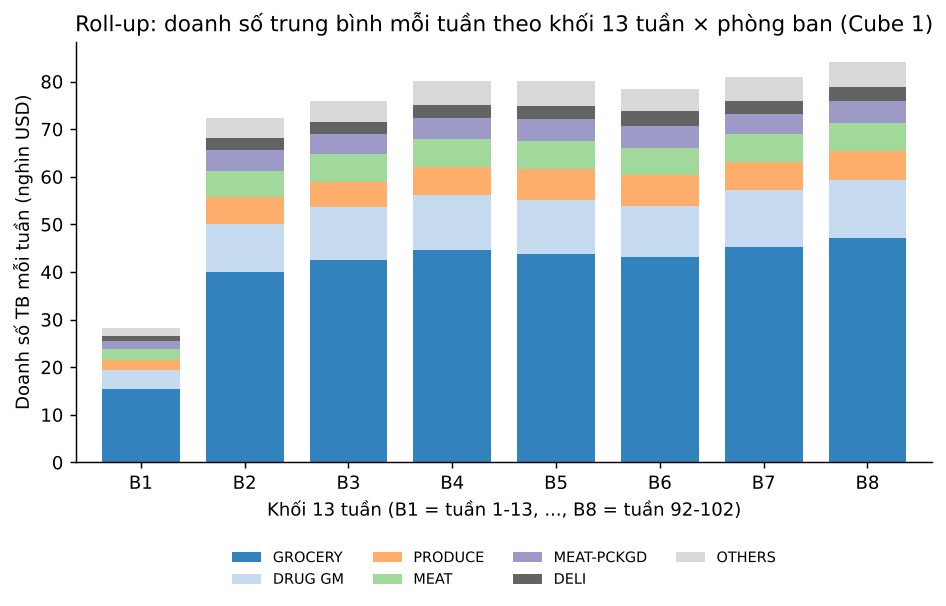

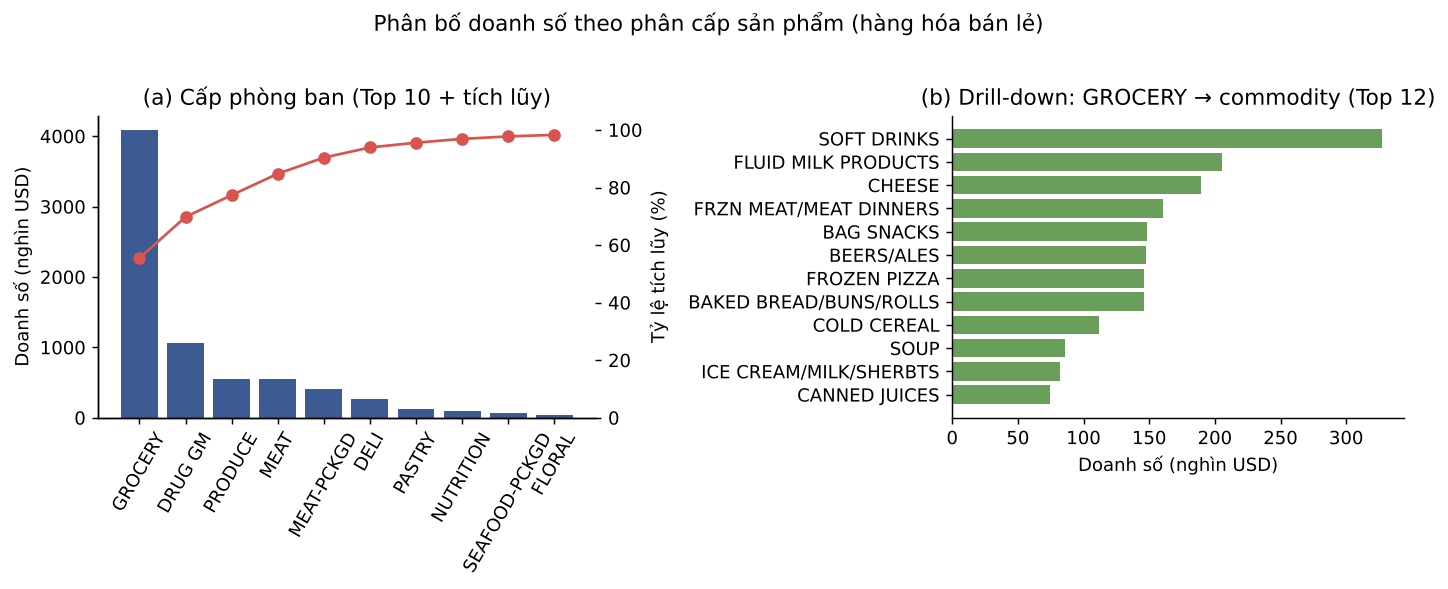

income_group  High (75K+)  Low (<35K)
department                           
DRUG GM          111555.0     71124.0
GROCERY          424775.0    286886.0
MEAT              48493.0     44510.0
PRODUCE           77782.0     36107.0


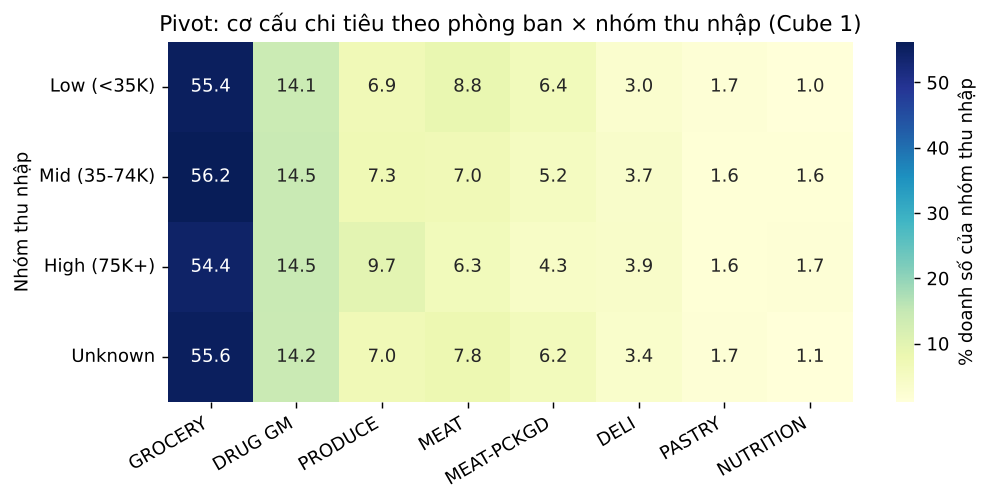

   income_group       sales  n_households  n_baskets  sales_per_household  \
0   High (75K+)  1396109.40           225      33447          6204.930667   
1    Low (<35K)   939258.96           212      36523          4430.466792   
2  Mid (35-74K)  1739083.93           364      55271          4777.703104   
3       Unknown  3297618.66          1699     125701          1940.917398   

   baskets_per_household  avg_basket  share_sales  
0             148.653333   41.740945     0.189378  
1             172.278302   25.716917     0.127408  
2             151.843407   31.464673     0.235902  
3              73.985285   26.233830     0.447312  


In [25]:
# ▶ ===== CUBE 1: SALES =====
# ROLL-UP: day -> week -> khối 13 tuần
blk = q(f"""select d.block_label, d.week_block, count(distinct d.week_no) n_weeks, sum(f.sales_value) sales,
            count(distinct f.basket_id) baskets, count(distinct f.household_key) households
            from fact_sales f join dim_date d on f.date_key=d.date_key where {BASE} group by 1,2 order by 2""")
blk["avg_basket_value"] = blk.sales / blk.baskets
blk["sales_per_week"] = blk.sales / blk.n_weeks
save(blk, "olap_rollup_block"); print(blk)
wk_tot = q(f"""select d.week_no, sum(f.sales_value) sales, count(distinct f.basket_id) baskets, count(distinct f.household_key) households
               from fact_sales f join dim_date d on f.date_key=d.date_key where {BASE} group by 1 order by 1""")
save(wk_tot, "olap_rollup_week")

# C1: doanh số trung bình mỗi tuần theo khối 13 tuần x phòng ban (stacked)
qd = q("select week_block, department, sales from cuboid_sales_week_block_department")
top = qd.groupby("department").sales.sum().nlargest(6).index.tolist()
qd["dept"] = qd.department.where(qd.department.isin(top), "OTHERS")
pv = qd.pivot_table(index="week_block", columns="dept", values="sales", aggfunc="sum").fillna(0)
pv = pv[top + ["OTHERS"]].div(blk.set_index("block_label").n_weeks, axis=0) / 1000
fig, ax = plt.subplots(figsize=(8.5, 4.2))
pv.plot(kind="bar", stacked=True, ax=ax, colormap="tab20c", width=0.75)
ax.set_xlabel("Khối 13 tuần (B1 = tuần 1-13, ..., B8 = tuần 92-102)"); ax.set_ylabel("Doanh số TB mỗi tuần (nghìn USD)")
ax.set_title("Roll-up: doanh số trung bình mỗi tuần theo khối 13 tuần × phòng ban (Cube 1)")
plt.xticks(rotation=0); ax.legend(ncol=4, fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18))
fig.savefig(FIG_DIR / "fig1_sales_block_department.png"); plt.show()

# DRILL-DOWN: GROCERY -> commodity; C2 = Pareto phòng ban + drill-down
dep = q("select department, sales, n_baskets from cuboid_sales_department order by sales desc")
dep["share"] = dep.sales / dep.sales.sum(); dep["cum_share"] = dep.share.cumsum()
save(dep, "olap_department_share")
gro = q(f"""select p.commodity, sum(f.sales_value) sales from fact_sales f join dim_product p on f.product_id=p.product_id
            where {BASE} and p.department='GROCERY' group by 1 order by 2 desc limit 12""")
save(gro, "olap_drilldown_grocery_commodity")
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [1.1, 1]})
d10 = dep.head(10)
axs[0].bar(d10.department, d10.sales / 1000, color="#3b5b92")
axs[0].set_ylabel("Doanh số (nghìn USD)"); axs[0].tick_params(axis="x", rotation=60)
a2 = axs[0].twinx(); a2.plot(d10.department, d10.cum_share * 100, "o-", color="#d9534f"); a2.set_ylim(0, 105)
a2.set_ylabel("Tỷ lệ tích lũy (%)"); a2.spines["top"].set_visible(False)
axs[0].set_title("(a) Cấp phòng ban (Top 10 + tích lũy)")
axs[1].barh(gro.commodity[::-1], gro.sales[::-1] / 1000, color="#6a9e5b")
axs[1].set_xlabel("Doanh số (nghìn USD)"); axs[1].set_title("(b) Drill-down: GROCERY → commodity (Top 12)")
fig.suptitle("Phân bố doanh số theo phân cấp sản phẩm (hàng hóa bán lẻ)", y=1.02); fig.tight_layout()
fig.savefig(FIG_DIR / "fig2_department_pareto_drilldown.png"); plt.show()

# SLICE (nửa sau: B5-B8 = tuần 53-102) và DICE (income in {Low, High}, 4 phòng ban chính)
sl = q(f"""select h.income_group, p.department, sum(f.sales_value) sales
           from fact_sales f join dim_date d on f.date_key=d.date_key join dim_product p on f.product_id=p.product_id
           join dim_household h on f.household_key=h.household_key
           where {BASE} and d.week_block>=5 group by 1,2""")
save(sl, "olap_slice_b5_b8_income_department")
dice = sl[sl.income_group.isin(["Low (<35K)", "High (75K+)"]) & sl.department.isin(["GROCERY", "DRUG GM", "PRODUCE", "MEAT"])]
dice_p = dice.pivot(index="department", columns="income_group", values="sales").round(0)  # PIVOT
save(dice_p.reset_index(), "olap_dice_pivot"); print(dice_p)

# C3: heatmap cơ cấu chi tiêu (row %) income_group × department - Pivot
sd = q("select income_group, department, sales from cuboid_sales_department_income_group")
top8 = sd.groupby("department").sales.sum().nlargest(8).index
hm = sd[sd.department.isin(top8)].pivot(index="income_group", columns="department", values="sales").reindex(INC_ORDER)
tot_inc = sd.groupby("income_group").sales.sum().reindex(INC_ORDER)
hm_pct = (hm.div(tot_inc, axis=0) * 100)[top8]
save(hm_pct.reset_index(), "olap_pivot_income_department_share")
fig, ax = plt.subplots(figsize=(8.5, 3.6))
sns.heatmap(hm_pct, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={"label": "% doanh số của nhóm thu nhập"}, ax=ax)
ax.set_xlabel(""); ax.set_ylabel("Nhóm thu nhập"); plt.xticks(rotation=30, ha="right")
ax.set_title("Pivot: cơ cấu chi tiêu theo phòng ban × nhóm thu nhập (Cube 1)")
fig.savefig(FIG_DIR / "fig3_income_department_heatmap.png"); plt.show()

inc = q("select income_group, sales, n_households, n_baskets from cuboid_sales_income_group")
inc["sales_per_household"] = inc.sales / inc.n_households
inc["baskets_per_household"] = inc.n_baskets / inc.n_households
inc["avg_basket"] = inc.sales / inc.n_baskets
inc["share_sales"] = inc.sales / inc.sales.sum()
save(inc, "olap_income_summary"); print(inc)

  campaign_type age_group income_group  n_targeted  n_redeemed  n_redemptions  \
0         TypeA       ALL          ALL        3979         635           1791   
1         TypeB       ALL          ALL        2655         210            454   
2         TypeC       ALL          ALL         574          44             73   

   spend_in_window  spend_pre90  n_households  redemption_rate  
0       1455030.90   2613564.87          1513           0.1596  
1        982752.96   2455016.21          1023           0.0791  
2        412291.52    553684.68           397           0.0767  


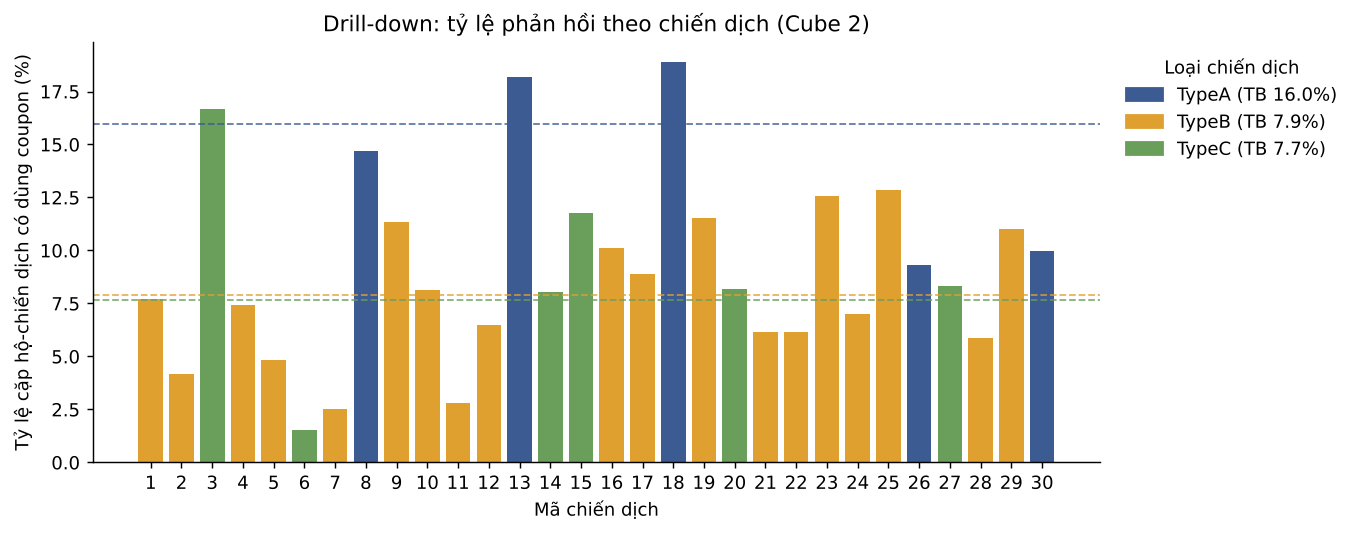

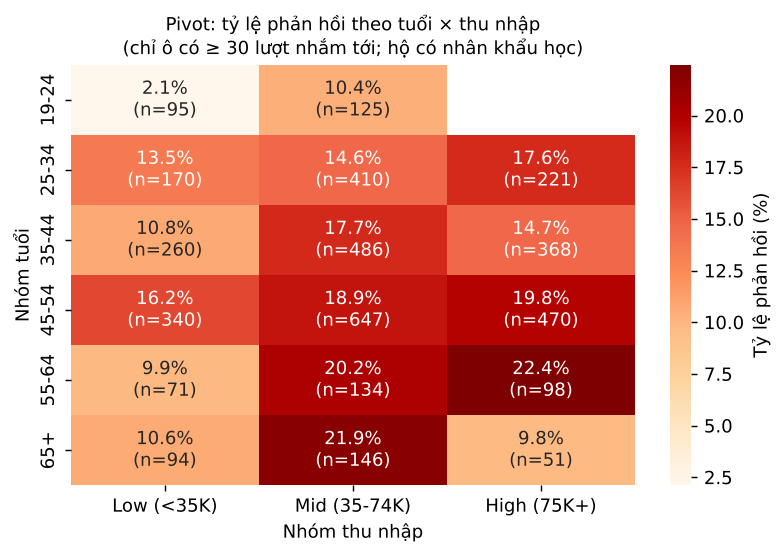

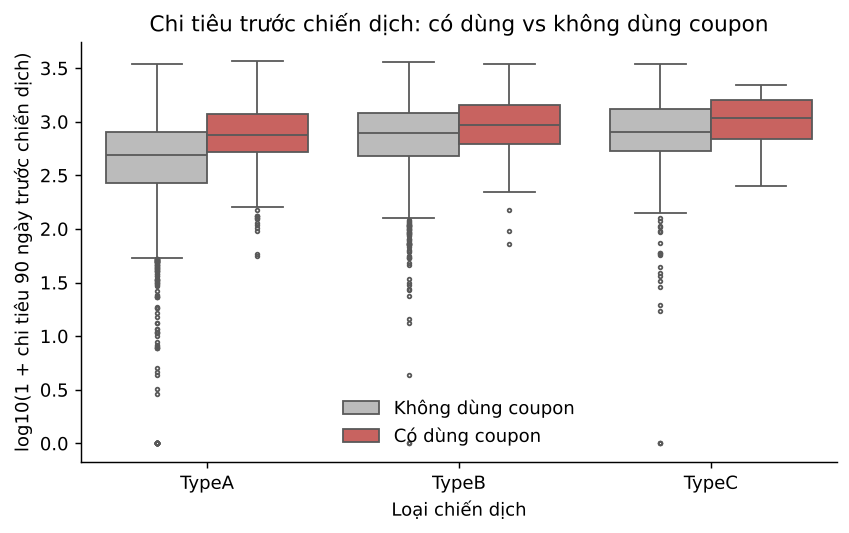

   redeemed_flag     n  mean_pre90  median_pre90  median_baskets  \
0              0  6319  755.994958        623.86            19.0   
1              1   889  950.656490        796.63            20.0   

   mean_in_window  mannwhitney_p  
0      373.449846   1.988981e-30  
1      551.457593   1.988981e-30  


In [26]:
# ▶ ===== CUBE 2: CAMPAIGN RESPONSE =====
ct = q("select * from cuboid_campaign_campaign_type").sort_values("campaign_type")
save(ct, "olap_rollup_campaign_type"); print(ct)
cmp_ = q("""select c.campaign_key, c.campaign_type, c.duration_days, count(*) n_targeted,
            sum(f.redeemed_flag) n_redeemed, sum(f.n_redemptions) n_redemptions
            from fact_campaign_response f join dim_campaign c on f.campaign_key=c.campaign_key group by 1,2,3""")
cmp_["redemption_rate"] = cmp_.n_redeemed / cmp_.n_targeted
cmp_ = cmp_.sort_values("campaign_key"); save(cmp_, "olap_drilldown_campaign")

colors = {"TypeA": "#3b5b92", "TypeB": "#e0a030", "TypeC": "#6a9e5b"}
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(cmp_.campaign_key.astype(str), cmp_.redemption_rate * 100, color=cmp_.campaign_type.map(colors))
for t, c in colors.items():
    ax.axhline(ct.loc[ct.campaign_type == t, "redemption_rate"].iat[0] * 100, color=c, ls="--", lw=1, alpha=.8)
ax.set_xlabel("Mã chiến dịch"); ax.set_ylabel("Tỷ lệ cặp hộ-chiến dịch có dùng coupon (%)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c, label=f"{t} (TB {ct.loc[ct.campaign_type==t,'redemption_rate'].iat[0]*100:.1f}%)") for t, c in colors.items()],
          frameon=False, title="Loại chiến dịch", loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title("Drill-down: tỷ lệ phản hồi theo chiến dịch (Cube 2)")
fig.savefig(FIG_DIR / "fig4_redemption_by_campaign.png"); plt.show()

ai = q("select age_group, income_group, n_targeted, n_redeemed, redemption_rate from cuboid_campaign_age_group_income_group")
save(ai, "olap_pivot_age_income_rate")
ai = ai[(ai.age_group != "Unknown") & (ai.income_group != "Unknown")]
rate = ai.pivot(index="age_group", columns="income_group", values="redemption_rate").reindex(AGE_ORDER[:-1])[INC_ORDER[:-1]] * 100
nn = ai.pivot(index="age_group", columns="income_group", values="n_targeted").reindex(AGE_ORDER[:-1])[INC_ORDER[:-1]]
annot = rate.round(1).astype(str) + "%\n(n=" + nn.fillna(0).astype(int).astype(str) + ")"
fig, ax = plt.subplots(figsize=(7, 4.2))
sns.heatmap(rate.where(nn >= 30), annot=annot.where(nn >= 30, ""), fmt="", cmap="OrRd", ax=ax,
            cbar_kws={"label": "Tỷ lệ phản hồi (%)"})
ax.set_xlabel("Nhóm thu nhập"); ax.set_ylabel("Nhóm tuổi")
ax.set_title("Pivot: tỷ lệ phản hồi theo tuổi × thu nhập\n(chỉ ô có ≥ 30 lượt nhắm tới; hộ có nhân khẩu học)", fontsize=10)
fig.savefig(FIG_DIR / "fig5_redemption_age_income.png"); plt.show()

dice2 = q("select * from cuboid_campaign_campaign_type_age_group where campaign_type in ('TypeA','TypeB') and age_group in ('35-44','45-54')")
save(dice2, "olap_dice_campaign_age")

fr = q("""select c.campaign_type, f.redeemed_flag, f.spend_pre90, f.baskets_pre90, f.spend_in_window
          from fact_campaign_response f join dim_campaign c on f.campaign_key=c.campaign_key""")
fr["log_spend"] = np.log10(1 + fr.spend_pre90)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
sns.boxplot(data=fr, x="campaign_type", y="log_spend", hue=fr.redeemed_flag.map({0: "Không dùng coupon", 1: "Có dùng coupon"}),
            palette=["#bbbbbb", "#d9534f"], ax=ax, fliersize=2, order=["TypeA", "TypeB", "TypeC"])
ax.set_xlabel("Loại chiến dịch"); ax.set_ylabel("log10(1 + chi tiêu 90 ngày trước chiến dịch)")
ax.legend(frameon=False, title=""); ax.set_title("Chi tiêu trước chiến dịch: có dùng vs không dùng coupon")
fig.savefig(FIG_DIR / "fig6_prespend_vs_redeemed.png"); plt.show()
summ = fr.groupby("redeemed_flag").agg(n=("spend_pre90", "size"), mean_pre90=("spend_pre90", "mean"),
                                       median_pre90=("spend_pre90", "median"), median_baskets=("baskets_pre90", "median"),
                                       mean_in_window=("spend_in_window", "mean")).reset_index()
u = mannwhitneyu(fr.loc[fr.redeemed_flag == 1, "spend_pre90"], fr.loc[fr.redeemed_flag == 0, "spend_pre90"])
summ["mannwhitney_p"] = u.pvalue; save(summ, "olap_prespend_by_redeemed"); print(summ)

In [27]:
# ▶ ===== CÁC TRUY VẤN OLAP BỔ SUNG =====
# (a) Khung giờ cao điểm (fact_sales.trans_hour): số giỏ phân biệt theo giờ
hr = q(f"""select f.trans_hour hour, count(distinct f.basket_id) baskets from fact_sales f where {BASE} group by 1 order by 1""")
hr["share"] = hr.baskets / hr.baskets.sum(); save(hr, "olap_hour_baskets")
win = {"00-09h": range(0, 10), "10-14h": range(10, 15), "15-19h": range(15, 20), "20-23h": range(20, 24)}
hw = pd.DataFrame([[k, hr[hr.hour.isin(list(v))].baskets.sum(), hr[hr.hour.isin(list(v))].share.sum()] for k, v in win.items()],
                  columns=["window", "baskets", "share"]); save(hw, "olap_hour_windows"); print(hw, hr.loc[hr.baskets.idxmax()])

# (b) Xếp hạng cửa hàng (dim_store x fact_sales)
st = q(f"""select f.store_id, s.store_tier, sum(f.sales_value) sales, count(distinct f.basket_id) baskets
           from fact_sales f join dim_store s on f.store_id=s.store_id where {BASE} group by 1,2 order by 3 desc""")
st["share"] = st.sales / st.sales.sum(); st["cum_share"] = st.share.cumsum(); save(st.head(10), "olap_store_top10")
st_info = pd.DataFrame({"n_stores": [len(st)], "top10_share": [st.head(10).share.sum()],
                        "top10pct_share": [st.head(int(len(st) * .1)).share.sum()],
                        "median_sales": [st.sales.median()], "max_sales": [st.sales.max()]}); save(st_info, "olap_store_summary"); print(st_info)

# (c) Lượt đổi coupon theo khối 13 tuần x loại chiến dịch + tuần cao điểm (drill-across fact_coupon_redemption <-> fact_sales qua dim_date)
rb = q("""select d.block_label, c.campaign_type, count(*) redemptions from fact_coupon_redemption r
          join dim_date d on r.date_key=d.date_key join dim_campaign c on r.campaign_key=c.campaign_key group by 1,2""")
rbp = rb.pivot(index="block_label", columns="campaign_type", values="redemptions").fillna(0).astype(int)
rbp["Total"] = rbp.sum(axis=1); save(rbp.reset_index(), "olap_redemption_block_type"); print(rbp)
rw = q("""select d.week_no, count(*) redemptions from fact_coupon_redemption r join dim_date d on r.date_key=d.date_key group by 1 order by 1""")
rw_all = pd.DataFrame({"week_no": range(1, 103)}).merge(rw, how="left", on="week_no").fillna(0)
save(rw.sort_values("redemptions", ascending=False).head(5), "olap_redemption_peak_weeks")
m = wk_tot.merge(rw_all, on="week_no"); m = m[m.week_no >= 16]       # bỏ 15 tuần đầu (giai đoạn đưa hộ vào bảng theo dõi, xem notebook 01)
corr_rs = m.sales.corr(m.redemptions)
pd.DataFrame({"pearson_weekly_sales_vs_redemptions_w16_102": [corr_rs], "n_weeks": [len(m)]}).to_csv(TAB_DIR / "olap_redemption_sales_corr.csv", index=False)
print("corr", corr_rs)

dt = q(f"""select f.sales_line_id, f.basket_id, f.date_key, f.household_key, f.product_id, f.quantity, f.sales_value, f.coupon_disc_amount
          from fact_sales f join dim_date d on f.date_key=d.date_key join dim_product p on f.product_id=p.product_id
          join dim_household h on f.household_key=h.household_key
          where d.block_label='B5' and p.department='PRODUCE' and h.income_group='High (75K+)' and {BASE}
          order by f.sales_value desc limit 5""")
save(dt, "olap_drillthrough_example"); print(dt)

   window  baskets     share
0  00-09h    21893  0.087243
1  10-14h    76640  0.305409
2  15-19h   111431  0.444051
3  20-23h    40978  0.163297 hour          17.000000
baskets    25145.000000
share          0.100202
Name: 17, dtype: float64


   n_stores  top10_share  top10pct_share  median_sales  max_sales
0       556     0.188506        0.675562        98.585  234398.29
campaign_type  TypeA  TypeB  TypeC  Total
block_label                              
B3                73      0      0     73
B4                56     30      2     88
B5               351     51      2    404
B6               616     73      8    697
B7               637    130     38    805
B8                58    170     23    251
corr 0.28564079263254377
   sales_line_id    basket_id  date_key  household_key  product_id  quantity  \
0        1350321  32957975859       404           1677      825180        11   
1        1293480  32760130294       389           2446    13944854         2   
2        1290657  32759803548       389           1609     1069312         1   
3        1451253  33316249492       429           2116     1069312         1   
4        1277493  32730331030       386           2123      951009         1   

   sales_value  coupon_dis

In [28]:
# ▶ Một số chỉ số tổng hợp
kp = q(f"""select count(distinct f.household_key) households, count(distinct f.basket_id) baskets, sum(f.sales_value) sales,
           count(*) lines from fact_sales f where {BASE}""")
red = q("select count(distinct household_key) hh_redeemed from fact_campaign_response where redeemed_flag=1")
tg = q("select count(distinct household_key) hh_targeted, count(*) pairs, sum(redeemed_flag) pos from fact_campaign_response")
conc = q("select household_key, sum(n_redemptions) r from fact_campaign_response group by 1 having r>0 order by r desc")
conc["cum"] = conc.r.cumsum() / conc.r.sum()
dd = q(f"""select count(distinct p.department) n_dept, count(distinct p.department||'|'||p.commodity) n_dept_comm
           from fact_sales f join dim_product p on f.product_id=p.product_id where {BASE}""")
pd.concat([kp, red, tg, dd], axis=1).assign(top10pct_hh_share=conc.cum.iloc[int(len(conc) * .1) - 1]).to_csv(TAB_DIR / "key_figures.csv", index=False)
print(pd.read_csv(TAB_DIR / "key_figures.csv").T)
con.close()

                              0
households         2.500000e+03
baskets            2.509420e+05
sales              7.372071e+06
lines              2.543426e+06
hh_redeemed        4.340000e+02
hh_targeted        1.584000e+03
pairs              7.208000e+03
pos                8.890000e+02
n_dept             2.900000e+01
n_dept_comm        3.330000e+02
top10pct_hh_share  3.787748e-01


---
## Bước 6 – Sơ đồ fact constellation và lattice các cuboid
Sơ đồ fact constellation được vẽ bằng matplotlib (**ô và chữ lớn, không cần cài Graphviz**): 3 bảng fact (đỏ) dùng chung các bảng chiều (xanh),
bảng cầu `bridge_coupon_product` (xanh lá) nối coupon – sản phẩm – chiến dịch.

In [29]:
# ▶ 6.1 Hàm vẽ sơ đồ fact constellation (ô to, chữ rõ)
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle

def draw_fact_constellation(path, dpi=170):
    """Sơ đồ fact constellation: ô to, chữ lớn, 3 bảng fact (đỏ) dùng chung các bảng chiều (xanh)."""
    FS, HS, RH, HH = 17, 18, 0.54, 0.70          # cỡ chữ nội dung / tiêu đề, chiều cao dòng / dòng tiêu đề (inch)
    C = {"fact": ("#c0504d", "#fde9d9"), "dim": ("#1f4e79", "#dce6f1"), "bridge": ("#4f7f3a", "#ebf1de")}
    T = {   # tên: (loại, các dòng)
     "fact_sales": ("fact", ["PK  sales_line_id", "FK  date_key", "FK  household_key", "FK  product_id", "FK  store_id",
                             "basket_id  (degenerate dim)", "quantity,  sales_value", "*_disc_amount  (3 cột)",
                             "*_raw  (giữ để truy vết)", "is_analysis_eligible", "exclusion_reason"]),
     "fact_coupon_redemption": ("fact", ["PK  redemption_id", "FK  date_key", "FK  household_key", "FK  coupon_upc",
                                         "FK  campaign_key", "redeemed_qty"]),
     "fact_campaign_response": ("fact", ["PK  response_id", "FK  household_key", "FK  campaign_key", "FK  start_ / end_date_key",
                                         "redeemed_flag", "n_redemptions", "spend_in_window", "spend_pre90, baskets_pre90"]),
     "dim_store": ("dim", ["PK  store_id", "store_tier", "total_sales_value"]),
     "dim_date": ("dim", ["PK  date_key  (DAY 1-719)", "week_no  (NULL nếu DAY>711)", "day_in_week", "week_block, block_label"]),
     "dim_household": ("dim", ["PK  household_key", "age_group", "income_desc / income_group", "hh_composition",
                               "household_size, kid_category", "homeowner, has_demographics"]),
     "dim_product": ("dim", ["PK  product_id", "department", "commodity", "sub_commodity", "brand, manufacturer",
                             "is_private_label", "is_non_merchandise"]),
     "dim_coupon": ("dim", ["PK  coupon_upc", "n_products", "n_campaigns"]),
     "dim_campaign": ("dim", ["PK  campaign_key", "campaign_type  (A / B / C)", "start_day / end_day", "duration_days"]),
     "bridge_coupon_product": ("bridge", ["FK  coupon_upc", "FK  product_id", "FK  campaign_key"]),
    }
    W = 5.1                                       # bề rộng mỗi ô (inch)
    COLX = {1: 0.4, 2: 0.4 + W + 0.7, 3: 0.4 + 2 * (W + 0.7)}
    H = {n: HH + RH * len(v[1]) for n, v in T.items()}
    GAP = 1.8
    h1 = max(H["dim_store"], H["dim_date"], H["dim_household"])
    h2 = max(H["fact_sales"], H["fact_coupon_redemption"], H["fact_campaign_response"])
    h3 = max(H["dim_product"], H["dim_coupon"], H["dim_campaign"]); hb = H["bridge_coupon_product"]
    fig_h = 1.7 + h1 + GAP + h2 + GAP + h3 + 1.6 + hb + 1.3
    bot1 = fig_h - 1.7 - h1; top2 = bot1 - GAP; top3 = top2 - h2 - GAP; top4 = top3 - h3 - 1.6
    fig_w = COLX[3] + W + 0.4
    place = {  # tên: (cột, y_trên)
     "dim_store": (1, bot1 + H["dim_store"]), "dim_date": (2, bot1 + H["dim_date"]), "dim_household": (3, bot1 + H["dim_household"]),
     "fact_sales": (1, top2), "fact_coupon_redemption": (2, top2), "fact_campaign_response": (3, top2),
     "dim_product": (1, top3), "dim_coupon": (2, top3), "dim_campaign": (3, top3),
     "bridge_coupon_product": (2, top4)}
    fig, ax = plt.subplots(figsize=(fig_w, fig_h)); ax.set_xlim(0, fig_w); ax.set_ylim(0, fig_h); ax.axis("off")
    box = {}
    for n, (col, ytop) in place.items():
        kind, rows = T[n]; hc, bg = C[kind]; x = COLX[col]; h = H[n]; y = ytop - h
        ax.add_patch(Rectangle((x, y), W, h, fc=bg, ec="#222222", lw=2.4, zorder=3))
        ax.add_patch(Rectangle((x, ytop - HH), W, HH, fc=hc, ec="#222222", lw=2.4, zorder=4))
        ax.text(x + W / 2, ytop - HH / 2, n, ha="center", va="center", color="white", fontsize=HS, fontweight="bold", zorder=5)
        for i, r in enumerate(rows):
            ty = ytop - HH - RH * (i + 0.5)
            ax.text(x + 0.18, ty, r, ha="left", va="center", fontsize=FS, zorder=5,
                    fontweight="bold" if r.startswith("PK") else "normal")
        box[n] = (x, y, W, h)
    def anchor(n, side, frac=0.5):
        x, y, w, h = box[n]
        return {"top": (x + w * frac, y + h), "bottom": (x + w * frac, y), "left": (x, y + h * frac), "right": (x + w, y + h * frac)}[side]
    def arrow(a, b, rad=0.0):
        ax.add_patch(FancyArrowPatch(a, b, arrowstyle="-|>", mutation_scale=30, lw=2.6, color="#444444",
                                     connectionstyle=f"arc3,rad={rad}", zorder=2, shrinkA=0, shrinkB=0))
    # cạnh: fact -> dim (khóa ngoại)
    arrow(anchor("fact_sales", "top", 0.25), anchor("dim_store", "bottom", 0.5))
    arrow(anchor("fact_sales", "top", 0.60), anchor("dim_date", "bottom", 0.18))
    arrow(anchor("fact_sales", "top", 0.90), anchor("dim_household", "bottom", 0.12))
    arrow(anchor("fact_sales", "bottom", 0.5), anchor("dim_product", "top", 0.5))
    arrow(anchor("fact_coupon_redemption", "top", 0.25), anchor("dim_date", "bottom", 0.55))
    arrow(anchor("fact_coupon_redemption", "top", 0.75), anchor("dim_household", "bottom", 0.35))
    arrow(anchor("fact_coupon_redemption", "bottom", 0.35), anchor("dim_coupon", "top", 0.35))
    arrow(anchor("fact_coupon_redemption", "bottom", 0.85), anchor("dim_campaign", "top", 0.12))
    arrow(anchor("fact_campaign_response", "top", 0.75), anchor("dim_household", "bottom", 0.80))
    arrow(anchor("fact_campaign_response", "top", 0.12), anchor("dim_date", "bottom", 0.88))
    arrow(anchor("fact_campaign_response", "bottom", 0.60), anchor("dim_campaign", "top", 0.60))
    # bridge -> dim
    arrow(anchor("bridge_coupon_product", "top", 0.5), anchor("dim_coupon", "bottom", 0.5))
    arrow(anchor("bridge_coupon_product", "top", 0.12), anchor("dim_product", "bottom", 0.85))
    arrow(anchor("bridge_coupon_product", "top", 0.88), anchor("dim_campaign", "bottom", 0.15))
    ax.text(fig_w / 2, fig_h - 0.7, "Fact constellation: 3 bảng fact dùng chung các bảng chiều", ha="center", va="center",
            fontsize=26, fontweight="bold", color="#222222")
    # chú giải
    lx, ly = 0.4, 0.55
    for i, (lab, k) in enumerate([("Bảng fact", "fact"), ("Bảng chiều (dimension)", "dim"), ("Bảng cầu (bridge)", "bridge")]):
        xx = lx + i * 4.6
        ax.add_patch(Rectangle((xx, ly), 0.5, 0.36, fc=C[k][0], ec="#222222", lw=1.6)); ax.text(xx + 0.65, ly + 0.18, lab, va="center", fontsize=16)
    ax.text(lx, ly - 0.45, "Mũi tên: khóa ngoại (FK) trỏ tới bảng chiều.   DD = degenerate dimension.", ha="left", va="center", fontsize=15, color="#333333")
    fig.savefig(path, dpi=dpi, bbox_inches="tight", facecolor="white"); plt.close(fig)

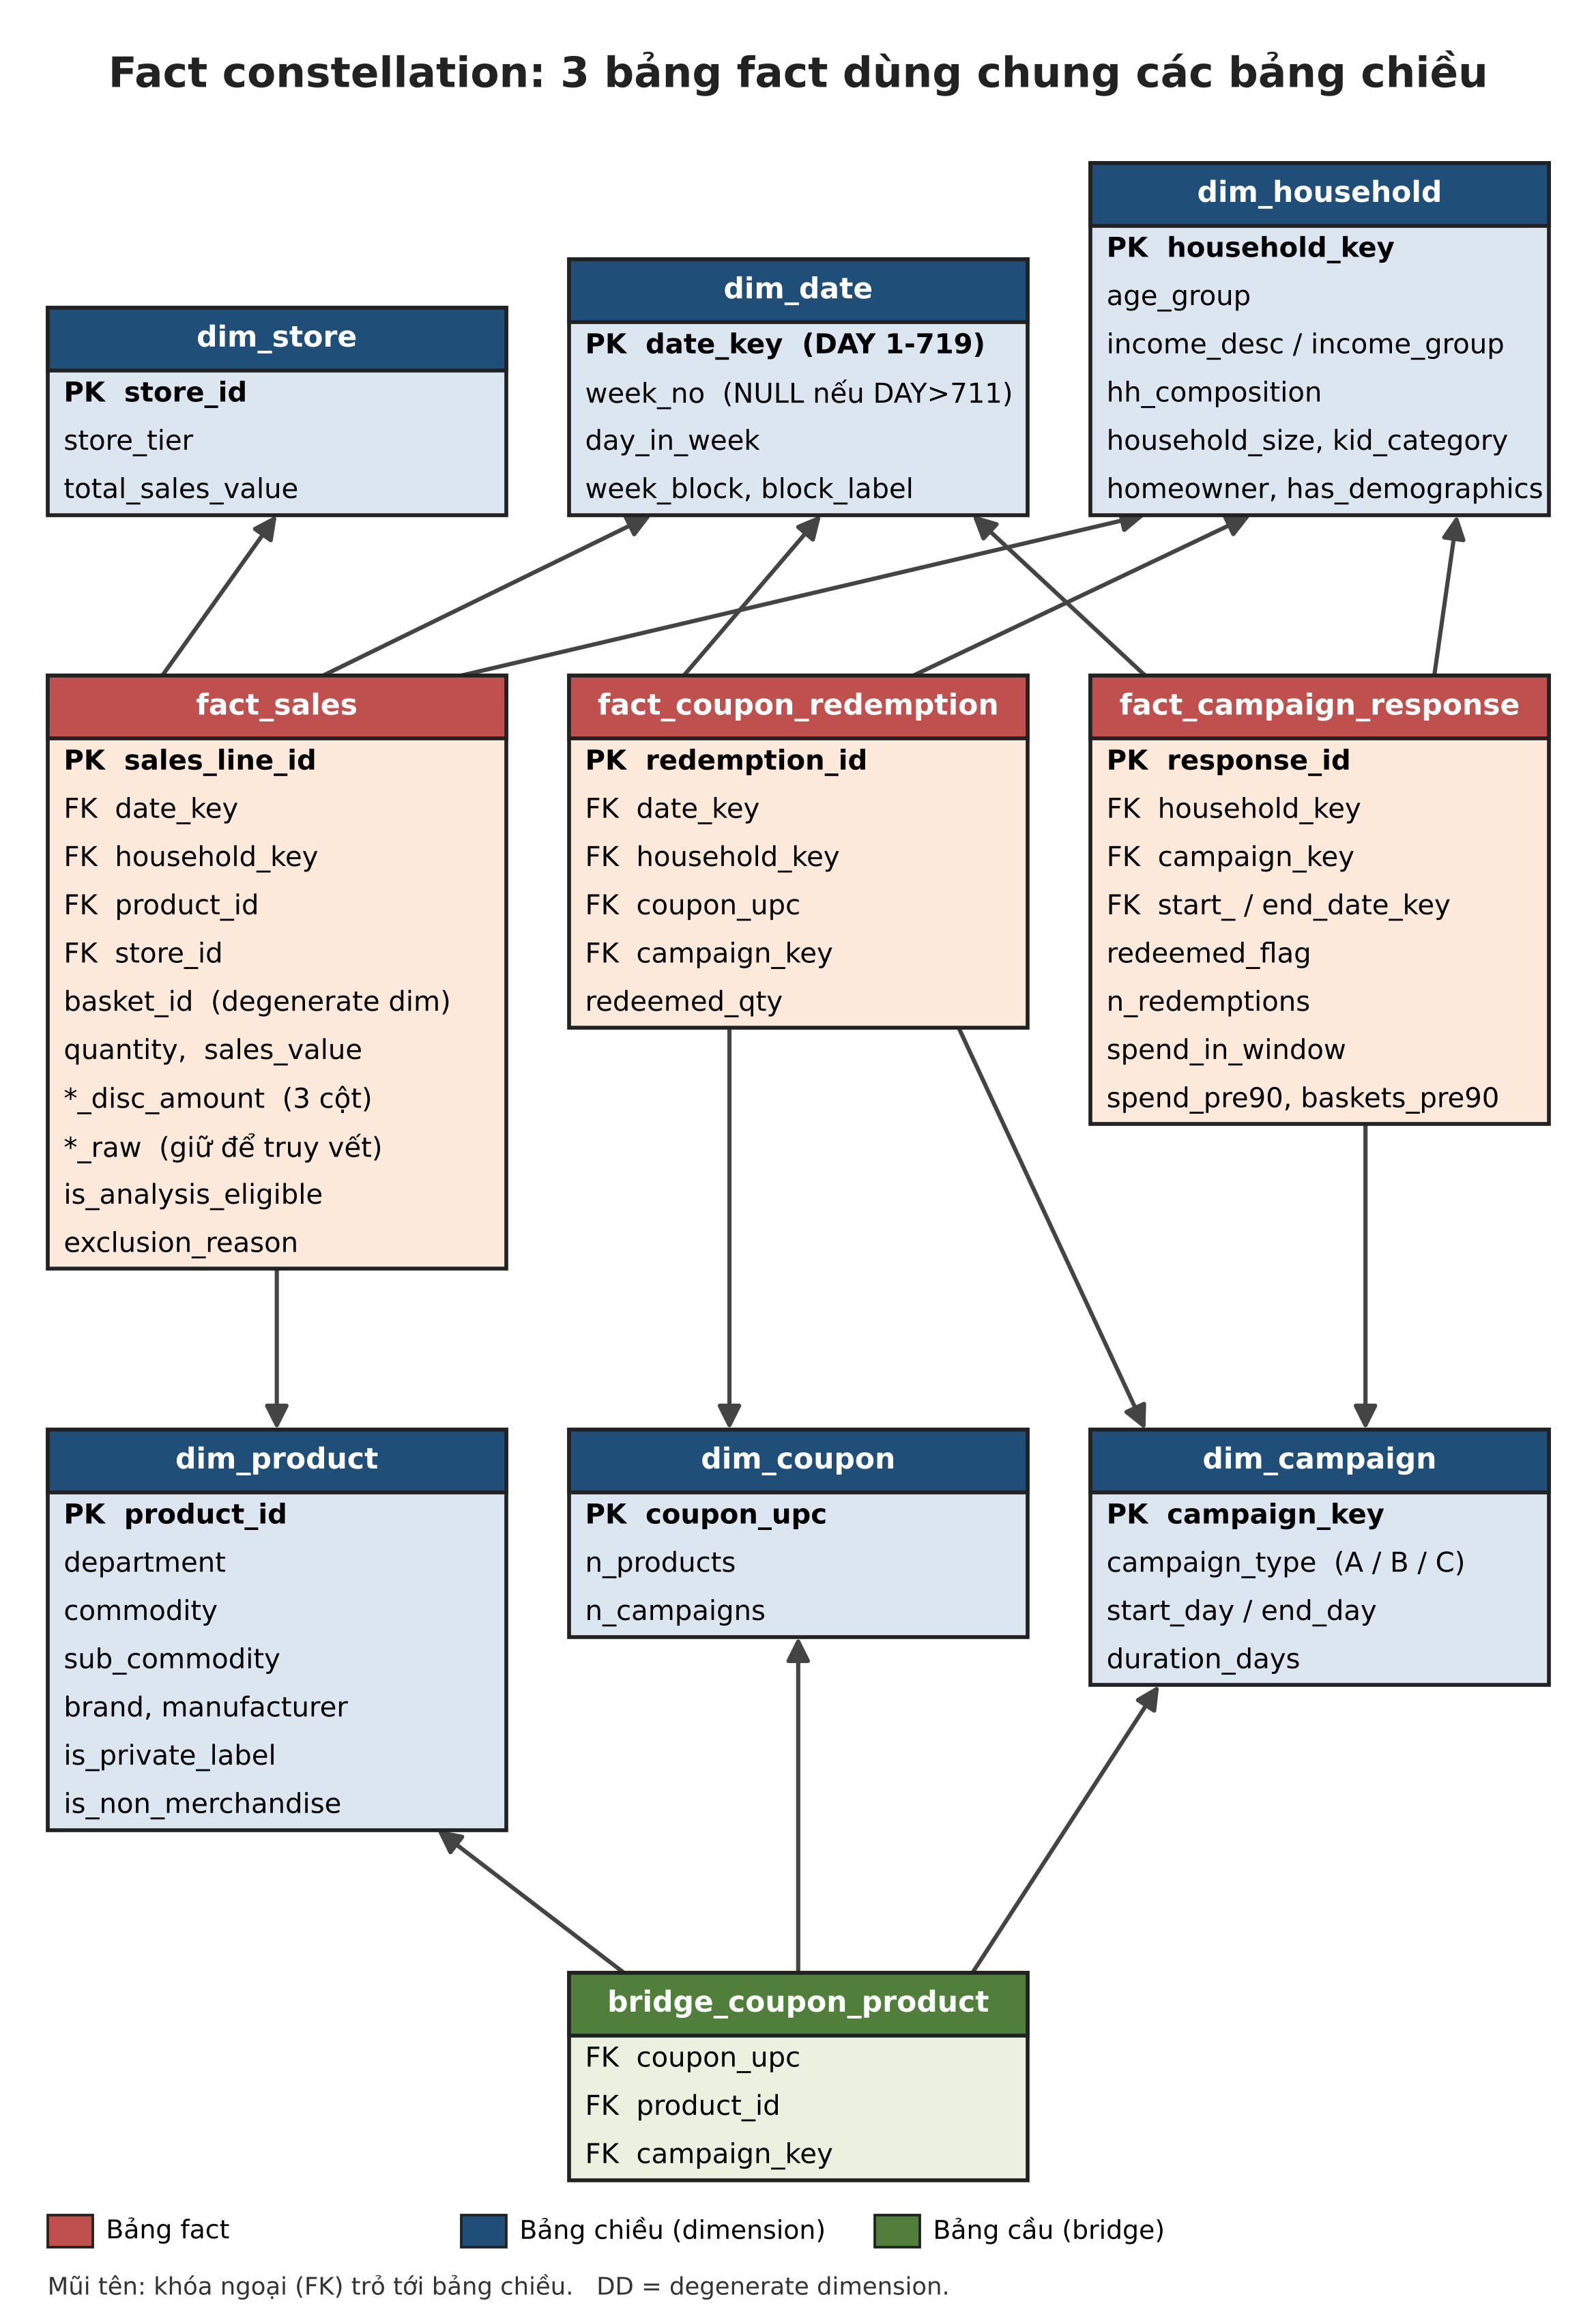

Đã lưu: ../figures/dw/fig_schema_fact_constellation.png


In [30]:
# ▶ 6.2 Vẽ và hiển thị sơ đồ fact constellation
from IPython.display import Image, display
CONSTELLATION_PNG = FIG_DIR / "fig_schema_fact_constellation.png"
draw_fact_constellation(CONSTELLATION_PNG, dpi=170)
display(Image(filename=str(CONSTELLATION_PNG), width=900))
print("Đã lưu:", CONSTELLATION_PNG)

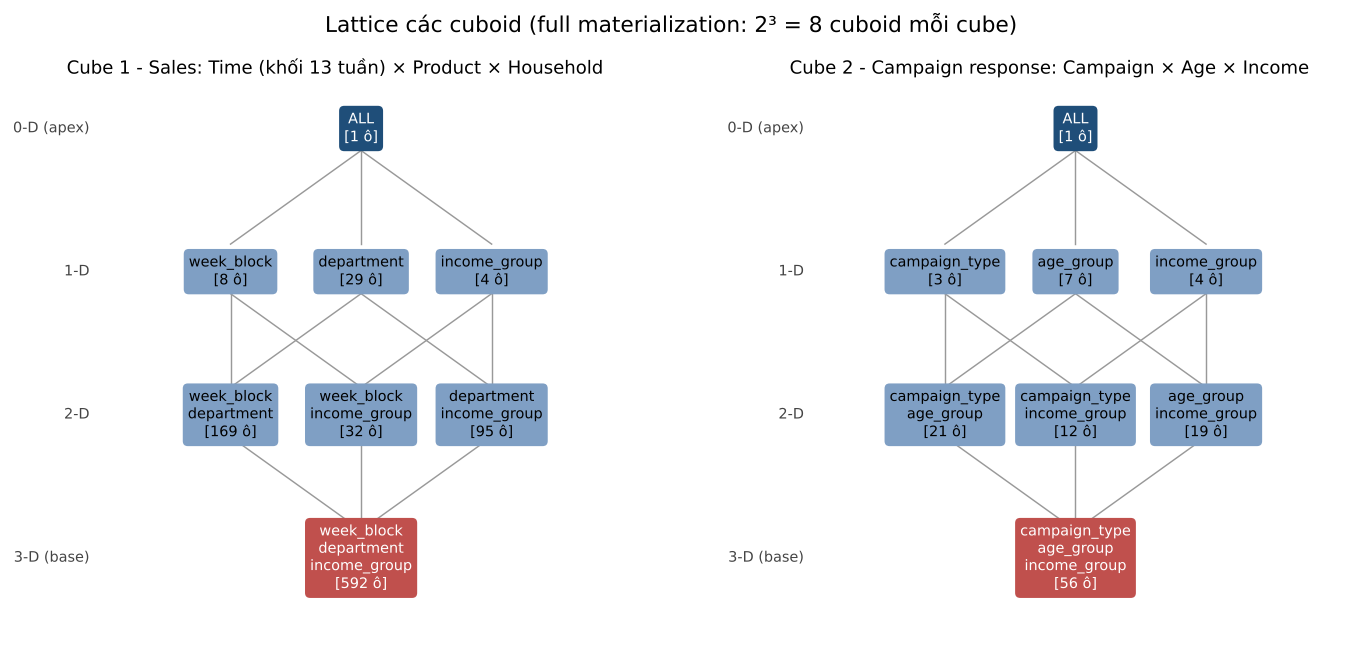

In [31]:
# ▶ 6.3 Lattice các cuboid cho 2 cube
import matplotlib.pyplot as plt
lat = pd.read_csv(TAB_DIR / "cube_lattice_cells.csv")
def draw_lattice(ax, cube, dims, title):
    cells = {tuple(c.split(" x ")) if "apex" not in c else (): n for c, n in zip(lat[lat.cube == cube].cuboid, lat[lat.cube == cube].n_cells)}
    pos = {(): (0.5, 0.92)}
    for k, y in [(1, 0.66), (2, 0.40), (3, 0.14)]:
        combos = list(itertools.combinations(dims, k))
        for i, c in enumerate(combos):
            pos[c] = ((i + 1) / (len(combos) + 1), y)
    for c in pos:
        for d in dims:
            if d in c:
                parent = tuple(x for x in c if x != d)
                ax.plot([pos[parent][0], pos[c][0]], [pos[parent][1] - .04, pos[c][1] + .05], color="#999", lw=.8, zorder=1)
    for c, (x, y) in pos.items():
        lbl = "ALL" if not c else "\n".join(c)
        col = "#c0504d" if len(c) == 3 else ("#1f4e79" if len(c) == 0 else "#7f9fc4")
        ax.text(x, y, f"{lbl}\n[{cells[c]} ô]", ha="center", va="center", fontsize=8, color="white" if len(c) in (0, 3) else "black",
                bbox=dict(boxstyle="round,pad=0.35", fc=col, ec="none"), zorder=2)
    for k, y, t in [(0, .92, "0-D (apex)"), (1, .66, "1-D"), (2, .40, "2-D"), (3, .14, "3-D (base)")]:
        ax.text(-0.02, y, t, ha="right", va="center", fontsize=8, color="#444")
    ax.set_xlim(-0.12, 1.02); ax.set_ylim(0, 1); ax.axis("off"); ax.set_title(title, fontsize=10)

fig, axs = plt.subplots(1, 2, figsize=(13, 5.5))
draw_lattice(axs[0], "Sales cube", ["week_block", "department", "income_group"], "Cube 1 - Sales: Time (khối 13 tuần) × Product × Household")
draw_lattice(axs[1], "Campaign cube", ["campaign_type", "age_group", "income_group"], "Cube 2 - Campaign response: Campaign × Age × Income")
fig.suptitle("Lattice các cuboid (full materialization: 2³ = 8 cuboid mỗi cube)")
fig.savefig(FIG_DIR / "fig_cuboid_lattice.png", dpi=140, bbox_inches="tight"); plt.show()

---
## Bước 7 – Đối chiếu số liệu chính
So sánh các con số chính của kho dữ liệu với số liệu ở notebook 01–02. Ô nào hiện `CHECK` nghĩa là số vừa tính khác số tham chiếu.

In [32]:
# ▶ 7.1 Đối chiếu số liệu chính với notebook 01–02
con = sqlite3.connect(DW_PATH)
one = lambda s: con.execute(s).fetchone()
ref = [
    ("Số dòng fact_sales",                   one("select count(*) from fact_sales")[0], 2_595_732),
    ("Số dòng đủ điều kiện phân tích",       one("select sum(is_analysis_eligible) from fact_sales")[0], 2_543_426),
    ("Số giỏ đủ điều kiện",                  one("select count(distinct basket_id) from fact_sales where is_analysis_eligible=1")[0], 250_942),
    ("Tổng doanh số đủ điều kiện (USD)",     round(one("select sum(sales_value) from fact_sales where is_analysis_eligible=1")[0]), 7_372_071),
    ("Số lượt đổi coupon",                   one("select count(*) from fact_coupon_redemption")[0], 2_318),
    ("Số cặp hộ-chiến dịch",                 one("select count(*) from fact_campaign_response")[0], 7_208),
    ("Số cặp hộ-chiến dịch có đổi coupon",   one("select sum(redeemed_flag) from fact_campaign_response")[0], 889),
    ("Số dòng dim_date",                     one("select count(*) from dim_date")[0], 719),
]
chk = pd.DataFrame(ref, columns=["Chỉ tiêu", "Vừa tính", "Tham chiếu"])
chk["Kết quả"] = np.where(chk["Vừa tính"] == chk["Tham chiếu"], "OK", "CHECK")
chk.to_csv(TAB_DIR / "final_sanity_check.csv", index=False)
print(chk.to_string(index=False))
con.close()

# ▶ 7.2 Danh sách file kết quả
for folder in (TAB_DIR, FIG_DIR):
    print(f"\n{folder}")
    for f in sorted(folder.glob("*")):
        print(f"  {f.name:48s} {f.stat().st_size/1e3:9.1f} KB")


                          Chỉ tiêu  Vừa tính  Tham chiếu Kết quả
                Số dòng fact_sales   2595732     2595732      OK
    Số dòng đủ điều kiện phân tích   2543426     2543426      OK
               Số giỏ đủ điều kiện    250942      250942      OK
  Tổng doanh số đủ điều kiện (USD)   7372071     7372071      OK
                Số lượt đổi coupon      2318        2318      OK
              Số cặp hộ-chiến dịch      7208        7208      OK
Số cặp hộ-chiến dịch có đổi coupon       889         889      OK
                  Số dòng dim_date       719         719      OK

../outputs/dw
  cube_lattice_cells.csv                                 0.6 KB
  dw_exclusion_reasons.csv                               0.1 KB
  dw_fact_quality_flags.csv                              0.2 KB
  dw_reconciliation.csv                                  0.3 KB
  dw_referential_integrity.csv                           0.8 KB
  dw_table_sizes.csv                                     0.2 KB
  final_sanity_c